<a href="https://colab.research.google.com/github/Najla-Nuricia/PemMes_244107020091_Najla/blob/main/JS09/JS09_Tugas02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub annoy faiss-cpu hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
import pandas as pd
import numpy as np
import time

import faiss
import hnswlib

from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [2]:
import kagglehub
import os
import glob

# Download dataset
path = kagglehub.dataset_download(
    "bwandowando/spotify-songs-with-attributes-and-lyrics"
)

print("Dataset berhasil didownload!")
print("Lokasi:", path)

# Cari file CSV
csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

print("\nDaftar file CSV:")
for i, file in enumerate(csv_files):
    print(i + 1, file)

100%|██████████| 894M/894M [00:11<00:00, 81.6MB/s]

Extracting files...


Dataset berhasil didownload!
Lokasi: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20

Daftar file CSV:
1 /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv
2 /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_lyrics_and_timestamps.csv


In [6]:
df = pd.read_csv(csv_files[0])

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (955320, 17)


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...


In [7]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

# Memastikan fitur tersedia
print("Fitur tersedia:")
print(df[features].dtypes)

# Mengubah fitur menjadi numerik
df[features] = df[features].apply(
    pd.to_numeric, errors='coerce'
)

# Menghapus data kosong dan infinity
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=features).reset_index(drop=True)

# Normalisasi menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# FAISS dan HNSW menggunakan float32
X_scaled = X_scaled.astype('float32')

print("Jumlah data setelah preprocessing:", len(df))
print("Dimensi data:", X_scaled.shape)
print("Rata-rata fitur:", X_scaled.mean(axis=0).round(3))
print("Standar deviasi:", X_scaled.std(axis=0).round(3))

Fitur tersedia:
danceability        float64
energy              float64
loudness            float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
dtype: object
Jumlah data setelah preprocessing: 955320
Dimensi data: (955320, 9)
Rata-rata fitur: [ 0. -0.  0.  0.  0.  0. -0.  0.  0.]
Standar deviasi: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
np.random.seed(42)

k = 10
n_query = min(100, len(X_scaled) - 1)

query_indices = np.random.choice(
    len(X_scaled),
    size=n_query,
    replace=False
)

queries = X_scaled[query_indices]

print("Jumlah query:", len(queries))
print("Jumlah nearest neighbors:", k)

Jumlah query: 100
Jumlah nearest neighbors: 10


In [9]:
from sklearn.neighbors import NearestNeighbors

exact_nn = NearestNeighbors(
    n_neighbors=k + 1,
    algorithm='brute',
    metric='euclidean',
    n_jobs=-1
)

start = time.perf_counter()

exact_nn.fit(X_scaled)

build_exact = time.perf_counter() - start

start = time.perf_counter()

exact_distances, exact_indices = exact_nn.kneighbors(queries)

query_exact = (
    time.perf_counter() - start
) / n_query

# Menghilangkan lagu query itu sendiri
def remove_self(indices, distances, query_indices, k):
    result_indices = []
    result_distances = []

    for i, row in enumerate(indices):
        pairs = [
            (idx, dist)
            for idx, dist in zip(row, distances[i])
            if idx != query_indices[i]
        ]

        pairs = pairs[:k]

        result_indices.append([x[0] for x in pairs])
        result_distances.append([x[1] for x in pairs])

    return (
        np.array(result_indices),
        np.array(result_distances)
    )

exact_indices, exact_distances = remove_self(
    exact_indices,
    exact_distances,
    query_indices,
    k
)

print("Exact NN")
print("Build time:", round(build_exact, 4), "seconds")
print("Query time:", round(query_exact * 1000, 4), "ms/query")

Exact NN
Build time: 0.0638 seconds
Query time: 5.2375 ms/query


In [10]:
annoy_index = AnnoyIndex(
    X_scaled.shape[1],
    'euclidean'
)

start = time.perf_counter()

for i, vector in enumerate(X_scaled):
    annoy_index.add_item(i, vector.tolist())

annoy_index.build(10)

build_annoy = time.perf_counter() - start

annoy_indices = []
annoy_distances = []

start = time.perf_counter()

for q in queries:
    ids, distances = annoy_index.get_nns_by_vector(
        q.tolist(),
        k + 1,
        search_k=-1,
        include_distances=True
    )

    annoy_indices.append(ids)
    annoy_distances.append(distances)

query_annoy = (
    time.perf_counter() - start
) / n_query

annoy_indices, annoy_distances = remove_self(
    np.array(annoy_indices),
    np.array(annoy_distances),
    query_indices,
    k
)

print("ANNOY")
print("Build time:", round(build_annoy, 4), "seconds")
print("Query time:", round(query_annoy * 1000, 4), "ms/query")

ANNOY
Build time: 27.2115 seconds
Query time: 0.0671 ms/query


In [11]:
import faiss

dimension = X_scaled.shape[1]

nlist = min(1000, max(4, int(np.sqrt(len(X_scaled)))))

quantizer = faiss.IndexFlatL2(dimension)

faiss_index = faiss.IndexIVFFlat(
    quantizer,
    dimension,
    nlist,
    faiss.METRIC_L2
)

faiss_index.nprobe = min(10, nlist)

start = time.perf_counter()

faiss_index.train(X_scaled)
faiss_index.add(X_scaled)

build_faiss = time.perf_counter() - start

start = time.perf_counter()

faiss_distances, faiss_indices = faiss_index.search(
    queries,
    k + 1
)

query_faiss = (
    time.perf_counter() - start
) / n_query

faiss_indices, faiss_distances = remove_self(
    faiss_indices,
    faiss_distances,
    query_indices,
    k
)

print("FAISS")
print("Build time:", round(build_faiss, 4), "seconds")
print("Query time:", round(query_faiss * 1000, 4), "ms/query")

FAISS
Build time: 1.7885 seconds
Query time: 0.1456 ms/query


In [12]:
import hnswlib

hnsw_index = hnswlib.Index(
    space='l2',
    dim=dimension
)

start = time.perf_counter()

hnsw_index.init_index(
    max_elements=len(X_scaled),
    ef_construction=200,
    M=16
)

hnsw_index.add_items(
    X_scaled,
    np.arange(len(X_scaled))
)

build_hnsw = time.perf_counter() - start

hnsw_index.set_ef(64)

start = time.perf_counter()

hnsw_indices, hnsw_distances = hnsw_index.knn_query(
    queries,
    k=k + 1
)

query_hnsw = (
    time.perf_counter() - start
) / n_query

hnsw_indices, hnsw_distances = remove_self(
    hnsw_indices,
    hnsw_distances,
    query_indices,
    k
)

print("HNSWLIB")
print("Build time:", round(build_hnsw, 4), "seconds")
print("Query time:", round(query_hnsw * 1000, 4), "ms/query")

HNSWLIB
Build time: 214.1727 seconds
Query time: 0.0725 ms/query


In [13]:
def calculate_recall(predictions, ground_truth):
    recalls = []

    for pred, truth in zip(predictions, ground_truth):
        score = len(
            set(pred) & set(truth)
        ) / len(truth)

        recalls.append(score)

    return np.mean(recalls) * 100


results = []

algorithms = {
    "Exact NN": (
        build_exact, query_exact, exact_indices
    ),
    "ANNOY": (
        build_annoy, query_annoy, annoy_indices
    ),
    "FAISS": (
        build_faiss, query_faiss, faiss_indices
    ),
    "HNSWLIB": (
        build_hnsw, query_hnsw, hnsw_indices
    )
}

for name, (build, query, predictions) in algorithms.items():

    recall = calculate_recall(
        predictions,
        exact_indices
    )

    results.append({
        "Algoritma": name,
        "Build Time (s)": round(build, 4),
        "Query Time (ms)": round(query * 1000, 4),
        "Recall@10 (%)": round(recall, 2)
    })

result_df = pd.DataFrame(results)

display(result_df)

,Algoritma,Build Time (s),Query Time (ms),Recall@10 (%)
0,Exact NN,0.0638,5.2375,100.0
1,ANNOY,27.2115,0.0671,81.4
2,FAISS,1.7885,0.1456,99.8
3,HNSWLIB,214.1727,0.0725,99.3


In [14]:
# Menentukan kolom nama lagu dan artis
track_col = next(
    (c for c in ['track_name', 'track', 'name']
     if c in df.columns),
    None
)

artist_col = next(
    (c for c in ['track_artist', 'artist_name', 'artist']
     if c in df.columns),
    None
)

def show_tracks(indices, query_number):
    query_id = query_indices[query_number]

    print("Query track:")
    print(df.iloc[query_id][
        [c for c in [track_col, artist_col] if c]
    ].to_dict())

    for name, (_, _, predictions) in algorithms.items():

        print(f"\n--- {name} ---")

        track_ids = predictions[query_number]

        columns = [
            c for c in [track_col, artist_col]
            if c is not None
        ]

        display(
            df.iloc[track_ids][columns].reset_index(drop=True)
        )

show_tracks(algorithms, 0)

Query track:
{'name': 'Dans La Nuit'}

--- Exact NN ---


,name
0,Blue (with Sarah Vaughan)
1,Revolutions
2,Blue (with Sarah Vaughan)
3,We Have All The Time In The World
4,"Vesti la giubba (From ""For the First Time"")"
5,Jupiter 4
6,Exsultate
7,Kahit Konting Pagtingin
8,This One's From The Heart
9,MORNING PRAYER



--- ANNOY ---


,name
0,Blue (with Sarah Vaughan)
1,Revolutions
2,Blue (with Sarah Vaughan)
3,We Have All The Time In The World
4,Jupiter 4
5,Exsultate
6,Kahit Konting Pagtingin
7,Roses Blue
8,What a Wonderful World
9,"Tosca (2002 Digital Remaster), Act II: Tosca, ..."



--- FAISS ---


,name
0,Blue (with Sarah Vaughan)
1,Revolutions
2,Blue (with Sarah Vaughan)
3,We Have All The Time In The World
4,"Vesti la giubba (From ""For the First Time"")"
5,Jupiter 4
6,Exsultate
7,Kahit Konting Pagtingin
8,This One's From The Heart
9,MORNING PRAYER



--- HNSWLIB ---


,name
0,Blue (with Sarah Vaughan)
1,Revolutions
2,Blue (with Sarah Vaughan)
3,We Have All The Time In The World
4,"Vesti la giubba (From ""For the First Time"")"
5,Jupiter 4
6,Exsultate
7,Kahit Konting Pagtingin
8,This One's From The Heart
9,MORNING PRAYER


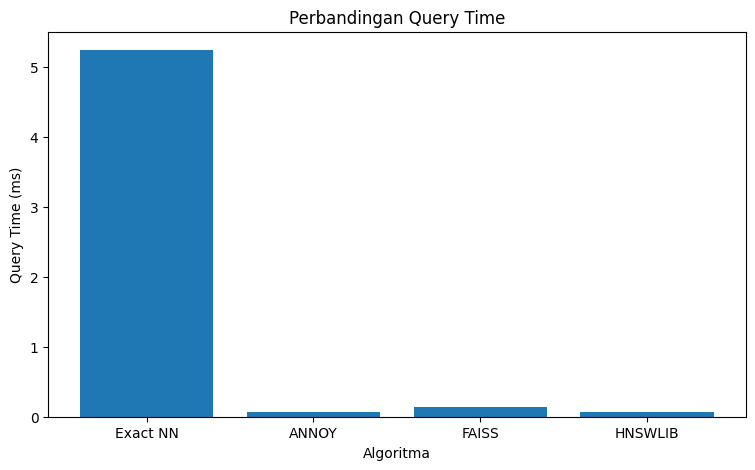

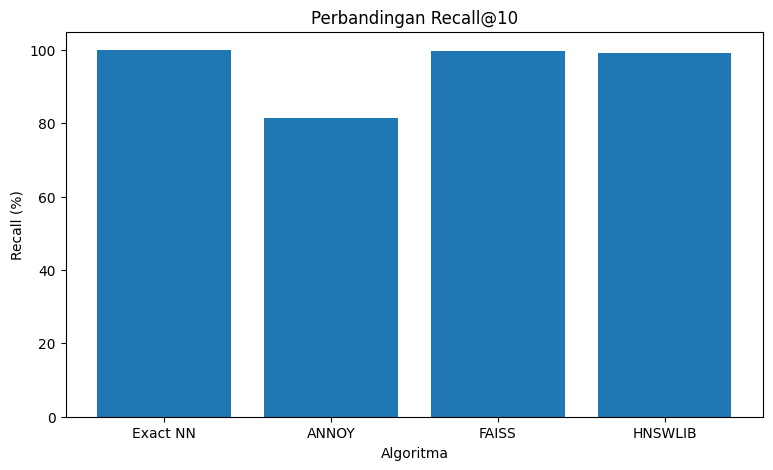

In [15]:
import matplotlib.pyplot as plt

# Perbandingan waktu pencarian
plt.figure(figsize=(9, 5))

plt.bar(
    result_df["Algoritma"],
    result_df["Query Time (ms)"]
)

plt.title("Perbandingan Query Time")
plt.xlabel("Algoritma")
plt.ylabel("Query Time (ms)")
plt.show()


# Perbandingan Recall
plt.figure(figsize=(9, 5))

plt.bar(
    result_df["Algoritma"],
    result_df["Recall@10 (%)"]
)

plt.title("Perbandingan Recall@10")
plt.xlabel("Algoritma")
plt.ylabel("Recall (%)")
plt.ylim(0, 105)
plt.show()

# kesimpulan



1. Kecepatan pencarian: Ketiga algoritma ANN memiliki waktu pencarian yang lebih cepat dibandingkan Exact NN. ANNOY memiliki waktu pencarian tercepat, yaitu 0,0671 ms, diikuti HNSWLIB sebesar 0,0725 ms dan FAISS sebesar 0,1456 ms.

2. ANNOY: Memiliki waktu pencarian paling cepat, tetapi nilai Recall@10 hanya sebesar 81,4%. Hal ini menunjukkan bahwa hasil pencariannya masih memiliki beberapa perbedaan dibandingkan Exact NN.

3. FAISS: Memberikan keseimbangan yang baik antara kecepatan dan akurasi. Dengan waktu pembangunan index 1,7885 detik, FAISS memperoleh Recall@10 sebesar 99,8%, sehingga hasilnya hampir sama dengan Exact NN.

4. HNSWLIB: Memiliki waktu pencarian yang cepat dengan Recall@10 sebesar 99,3%. Namun, waktu pembangunan index mencapai 214,1727 detik, paling lama dibandingkan algoritma lainnya.

5. Exact NN: Menghasilkan akurasi tertinggi dengan Recall@10 sebesar 100%. Namun, waktu pencariannya paling lama, yaitu 5,2375 ms per query.

6. Perbandingan hasil pencarian: Pada contoh query pertama, hasil FAISS dan HNSWLIB sama dengan Exact NN. Sementara itu, ANNOY menghasilkan beberapa perbedaan lagu, seperti "Roses Blue" dan "What a Wonderful World".